# Segmentación de peces: YOLOv8-seg vs YOLO11-seg vs SOLOv2

1. Carga de datos desde `DATA_URL` (imagen + máscara según `segmentacion/manifest.json`) y guardado como dataset.
2. Split train/val/test estratificado por especie y **agrupado por `group`** (fotos casi duplicadas no se separan entre splits).
3. Entrenamiento de YOLOv8n-seg, YOLO11n-seg y SOLOv2 (light R18), pensado para una GTX 1650 de 4 GB.
4. Comparación de métricas en el conjunto de validación.

La segmentación tiene **una sola clase: `pescado`**. La especie solo se usa para estratificar el split.

In [2]:
import json, shutil, time, subprocess, sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

DATA_URL = Path(r"D:\datasets\PRUEBAS")   # contiene imagenes/ y segmentacion/
OUT = Path("dataset").resolve()            # dataset generado (junto al notebook)
RUNS = Path("runs").resolve()              # salidas de entrenamiento y resultados
SEED = 42
CLASS_NAME = "pescado"

OUT.mkdir(exist_ok=True); RUNS.mkdir(exist_ok=True)

## 1. Cargar imágenes + máscaras y guardar el dataset

In [7]:
manifest = json.loads((DATA_URL / "segmentacion" / "manifest.json").read_text(encoding="utf-8"))

def read(path, flags):
    # np.fromfile + imdecode: soporta rutas con caracteres no ASCII en Windows
    return cv2.imdecode(np.fromfile(str(path), np.uint8), flags)

def mask_to_polygons(mask, min_rel_area=0.10, eps_rel=0.001):
    '''Máscara binaria -> lista de polígonos [x1,y1,x2,y2,...] en píxeles.
    Descarta fragmentos con área < min_rel_area * el contorno más grande.'''
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return []
    biggest = max(cv2.contourArea(c) for c in cnts)
    polys = []
    for c in cnts:
        if cv2.contourArea(c) < min_rel_area * biggest:
            continue
        c = cv2.approxPolyDP(c, eps_rel * cv2.arcLength(c, True), True)
        if len(c) >= 3:
            polys.append(c.reshape(-1).astype(float).tolist())
    return polys

records, skipped = [], []
for key, m in manifest.items():
    if m.get("status") != "accepted":
        continue
    img_path = DATA_URL / "imagenes" / key
    mask_path = DATA_URL / "segmentacion" / m["mask"].replace("\\", "/")
    if not img_path.exists() or not mask_path.exists():
        skipped.append((key, "falta imagen o máscara en disco")); continue
    img = read(img_path, cv2.IMREAD_COLOR)
    mask = read(mask_path, cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        skipped.append((key, "no se pudo leer")); continue
    h, w = img.shape[:2]
    if mask.shape != (h, w):
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
    polys = mask_to_polygons((mask > 0).astype(np.uint8))
    if not polys:
        skipped.append((key, "máscara vacía")); continue
    records.append(dict(file=key, img_path=str(img_path), species=m["species"],
                        group=m["group"], width=w, height=h, polygons=polys))

(OUT / "records.json").write_text(json.dumps(records), encoding="utf-8")
print(f"{len(records)} imágenes cargadas, {len(skipped)} omitidas {skipped[:5]}")
pd.DataFrame(records).species.value_counts()

1316 imágenes cargadas, 1 omitidas [('sabalo/372525581_680725616.jpg', 'falta imagen o máscara en disco')]


species
palometa          357
tararira          271
sabalo            269
dorado            188
boga              127
surubi_pintado    104
Name: count, dtype: int64

## 2. Split train/val/test (70/15/15) estratificado por especie y agrupado por `group`

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

df = pd.DataFrame(records)

# 20 folds de ~5%: 3 -> test (15%), 3 -> val (15%), 14 -> train (70%).
# StratifiedGroupKFold mantiene la proporción de especies en cada fold y
# nunca reparte un mismo `group` entre folds.
K = 20
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
for fold, (_, idx) in enumerate(sgkf.split(df, df.species, df.group)):
    df.loc[idx, "fold"] = fold
df["split"] = np.select([df.fold < 3, df.fold < 6], ["test", "val"], default="train")

# Verificaciones
assert (df.groupby("group").split.nunique() == 1).all(), "hay grupos repartidos entre splits"
print("Imágenes por split y especie:")
print(pd.crosstab(df.species, df.split, margins=True)[["train", "val", "test", "All"]])
print("\nProporción por especie (cada fila suma 1):")
print(pd.crosstab(df.species, df.split, normalize="index").round(3)[["train", "val", "test"]])
print("\nProporción global:", df.split.value_counts(normalize=True).round(3).to_dict())

Imágenes por split y especie:
split           train  val  test   All
species                               
boga               79   16    32   127
dorado            131   29    28   188
palometa          250   54    53   357
sabalo            188   41    40   269
surubi_pintado     74   15    15   104
tararira          191   39    41   271
All               913  194   209  1316

Proporción por especie (cada fila suma 1):
split           train    val   test
species                            
boga            0.622  0.126  0.252
dorado          0.697  0.154  0.149
palometa        0.700  0.151  0.148
sabalo          0.699  0.152  0.149
surubi_pintado  0.712  0.144  0.144
tararira        0.705  0.144  0.151

Proporción global: {'train': 0.694, 'test': 0.159, 'val': 0.147}


## 2b. Exportar el dataset a formato YOLO-seg y COCO (clase única `pescado`)

In [9]:
# Se regenera desde cero: si cambia el split, no quedan imágenes viejas en otra carpeta
for d in ("images", "labels"):
    shutil.rmtree(OUT / d, ignore_errors=True)
for split in ["train", "val", "test"]:
    (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)

def dst_name(r):
    '''Nombre único en el dataset: especie__archivo. YOLO no lee .jpe, así que se guarda como .jpg
    (es el mismo JPEG; el manifest y los originales no se tocan, y el label comparte el stem).'''
    p = Path(r["file"])
    suffix = ".jpg" if p.suffix.lower() == ".jpe" else p.suffix
    return f"{r['species']}__{p.stem}{suffix}"

_names = df.apply(dst_name, axis=1).str.lower()
_dup = _names[_names.duplicated(keep=False)]
assert _dup.empty, f"nombres de destino duplicados: {df.loc[_dup.index, 'file'].tolist()}"

coco = {s: dict(images=[], annotations=[], categories=[dict(id=1, name=CLASS_NAME)]) for s in ["train", "val", "test"]}
ann_id = 1
for img_id, r in enumerate(df.to_dict("records"), start=1):
    s = r["split"]
    name = dst_name(r)
    dst = OUT / "images" / s / name
    shutil.copy2(r["img_path"], dst)
    w, h = r["width"], r["height"]

    lines = []
    coco[s]["images"].append(dict(id=img_id, file_name=name, width=w, height=h))
    for poly in r["polygons"]:
        xy = np.array(poly).reshape(-1, 2)
        norm = (xy / [w, h]).clip(0, 1).reshape(-1)
        lines.append("0 " + " ".join(f"{v:.6f}" for v in norm))
        x0, y0 = xy.min(0); x1, y1 = xy.max(0)
        coco[s]["annotations"].append(dict(
            id=ann_id, image_id=img_id, category_id=1, iscrowd=0,
            segmentation=[poly], bbox=[float(x0), float(y0), float(x1 - x0), float(y1 - y0)],
            area=float(cv2.contourArea(xy.astype(np.float32)))))
        ann_id += 1
    (OUT / "labels" / s / (Path(name).stem + ".txt")).write_text("\n".join(lines))

for s, d in coco.items():
    (OUT / f"coco_{s}.json").write_text(json.dumps(d))

(OUT / "data.yaml").write_text(
    f"path: {OUT.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n"
    f"names:\n  0: {CLASS_NAME}\n")
df.drop(columns=["polygons"]).to_csv(OUT / "split.csv", index=False)
print({s: len(d["images"]) for s, d in coco.items()}, "-> dataset en", OUT)

{'train': 913, 'val': 194, 'test': 209} -> dataset en C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset


## 3. Entrenamiento YOLO-seg

Hiperparámetros "promedio" para una GTX 1650 (4 GB): modelos `n` (nano), `imgsz=640`, `batch=8`, 100 épocas con early stopping
(`patience=25`), `optimizer="auto"`, `lr0=0.01`, mosaic + HSV + flip horizontal (sin flip vertical: los peces no aparecen invertidos).
El resultado en validación se guarda en `runs/results_<modelo>.json`.

In [3]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

HYP = dict(epochs=100, patience=25, imgsz=640, batch=8, workers=2, optimizer="auto",
           lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3,
           cos_lr=False, close_mosaic=10, mosaic=1.0, fliplr=0.5, flipud=0.0,
           hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, amp=True, seed=SEED, deterministic=True)

CONF = 0.25   # umbral de confianza para la métrica de IoU (igual en YOLO y SOLOv2)

def gt_mask(polys, h, w):
    m = np.zeros((h, w), np.uint8)
    for p in polys:
        cv2.fillPoly(m, [np.round(np.array(p).reshape(-1, 2)).astype(np.int32)], 1)
    return m.astype(bool)

def mean_iou_yolo(model, split="val"):
    '''IoU medio por imagen entre la unión de máscaras predichas y la máscara real (clase única).'''
    ious = []
    for r in df[df.split == split].to_dict("records"):
        f = OUT / "images" / split / dst_name(r)
        h, w = r["height"], r["width"]
        pred = model.predict(str(f), imgsz=HYP["imgsz"], conf=CONF, retina_masks=True, verbose=False)[0]
        pm = np.zeros((h, w), bool)
        if pred.masks is not None:
            pm = pred.masks.data.cpu().numpy().any(0)
            if pm.shape != (h, w):
                pm = cv2.resize(pm.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        gm = gt_mask(r["polygons"], h, w)
        ious.append((pm & gm).sum() / max((pm | gm).sum(), 1))
    return float(np.mean(ious))

def plot_training(log, name, best_epoch):
    '''Curvas de entrenamiento desde results.csv: loss total y de máscara (train vs val) y mAP de máscara en val.'''
    tr = [c for c in log.columns if c.startswith("train/") and c.endswith("_loss")]
    va = [c for c in log.columns if c.startswith("val/") and c.endswith("_loss")]
    ep = log["epoch"]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    axes[0].plot(ep, log[tr].sum(axis=1), label="train"); axes[0].plot(ep, log[va].sum(axis=1), label="val")
    axes[0].set_title("Loss total (box+seg+cls+dfl)")
    axes[1].plot(ep, log["train/seg_loss"], label="train"); axes[1].plot(ep, log["val/seg_loss"], label="val")
    axes[1].set_title("Loss de máscara (seg_loss)")
    axes[2].plot(ep, log["metrics/mAP50(M)"], label="mAP50"); axes[2].plot(ep, log["metrics/mAP50-95(M)"], label="mAP50-95")
    axes[2].set_title("mAP de máscara en val (sube)")
    for ax in axes:
        ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"mejor época ({best_epoch})")
        ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend()
    fig.suptitle(name); plt.tight_layout(); fig.savefig(RUNS / f"curves_{name}.png", dpi=110); plt.show()

def train_and_eval(weights, name):
    t0 = time.time()
    model = YOLO(weights)
    model.train(data=str(OUT / "data.yaml"), project=str(RUNS), name=name, exist_ok=True, **HYP)
    train_min = (time.time() - t0) / 60

    best = YOLO(RUNS / name / "weights" / "best.pt")
    m = best.val(data=str(OUT / "data.yaml"), split="val", imgsz=HYP["imgsz"], batch=8, workers=2,
                 project=str(RUNS), name=f"{name}_val", exist_ok=True)
    miou = mean_iou_yolo(best)
    log = pd.read_csv(RUNS / name / "results.csv"); log.columns = log.columns.str.strip()
    row = log.loc[log["metrics/mAP50-95(M)"].idxmax()]      # época del mejor modelo
    print(f"[{name}] IoU medio val = {miou:.3f} | val seg_loss = {row['val/seg_loss']:.3f} "
          f"| val box_loss = {row['val/box_loss']:.3f} (época {int(row['epoch'])})")
    res = dict(model=name, mean_iou=miou, val_seg_loss=float(row["val/seg_loss"]),
               train_loss_last=None, params_M=sum(p.numel() for p in best.model.parameters()) / 1e6,
               train_min=train_min, infer_ms=m.speed["inference"],
               mask_map50=m.seg.map50, mask_map50_95=m.seg.map, mask_precision=m.seg.mp, mask_recall=m.seg.mr,
               box_map50=m.box.map50, box_map50_95=m.box.map, box_precision=m.box.mp, box_recall=m.box.mr)
    (RUNS / f"results_{name}.json").write_text(json.dumps(res, indent=1))
    plot_training(log, name, int(row["epoch"]))
    return res

In [11]:
# YOLOv8-seg (nano)
res_v8 = train_and_eval("yolov8n-seg.pt", "yolov8n-seg")
res_v8

New https://pypi.org/project/ultralytics/8.4.186 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

{'model': 'yolov8n-seg',
 'mean_iou': 0.921191197150671,
 'val_seg_loss': 0.68767,
 'train_loss_last': None,
 'params_M': 3.263811,
 'train_min': 65.10888808965683,
 'infer_ms': 8.37013247423174,
 'mask_map50': np.float64(0.9929561755675886),
 'mask_map50_95': np.float64(0.9336557780076067),
 'mask_precision': np.float64(0.9882542515348587),
 'mask_recall': np.float64(0.979381443298969),
 'box_map50': np.float64(0.9926935369338539),
 'box_map50_95': np.float64(0.9083070949368983),
 'box_precision': np.float64(0.9882542515348587),
 'box_recall': np.float64(0.979381443298969)}

### Ejemplos de validación (YOLOv8n-seg): mayor confianza, menor confianza y fallos

Se predice sobre `val` con `conf=0.05` para poder ver detecciones débiles. En cada imagen se dibuja la predicción de YOLO (máscara, caja y confianza) y el contorno real en verde.
1. **Mayor confianza:** las 16 imágenes con la confianza máxima más alta.
2. **Menor confianza:** las 16 imágenes con detección cuya confianza máxima es la más baja.
3. **Detecta fondo / no detecta el pez:** las 16 con menor IoU (con `conf>=0.25`, igual que la métrica). Primero las que predicen algo con IoU 0 (máscara sobre el fondo), luego las sin detección.

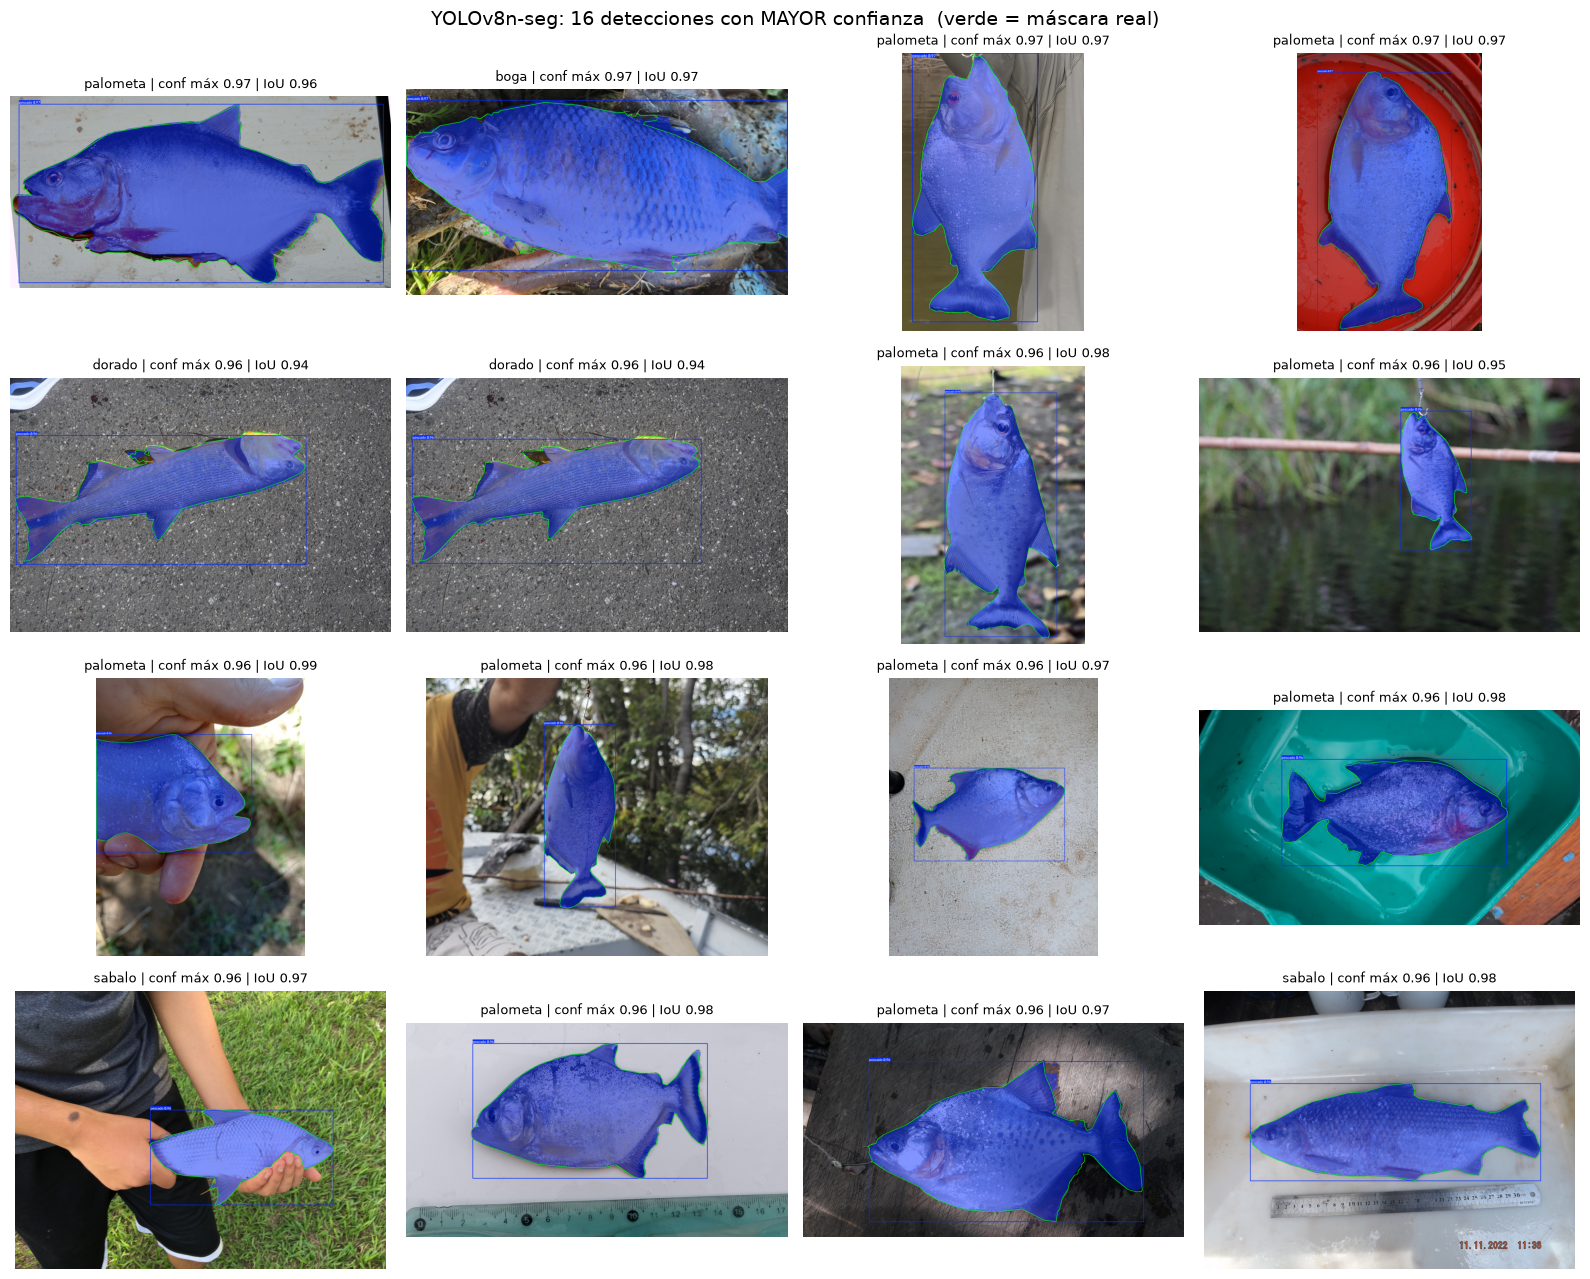

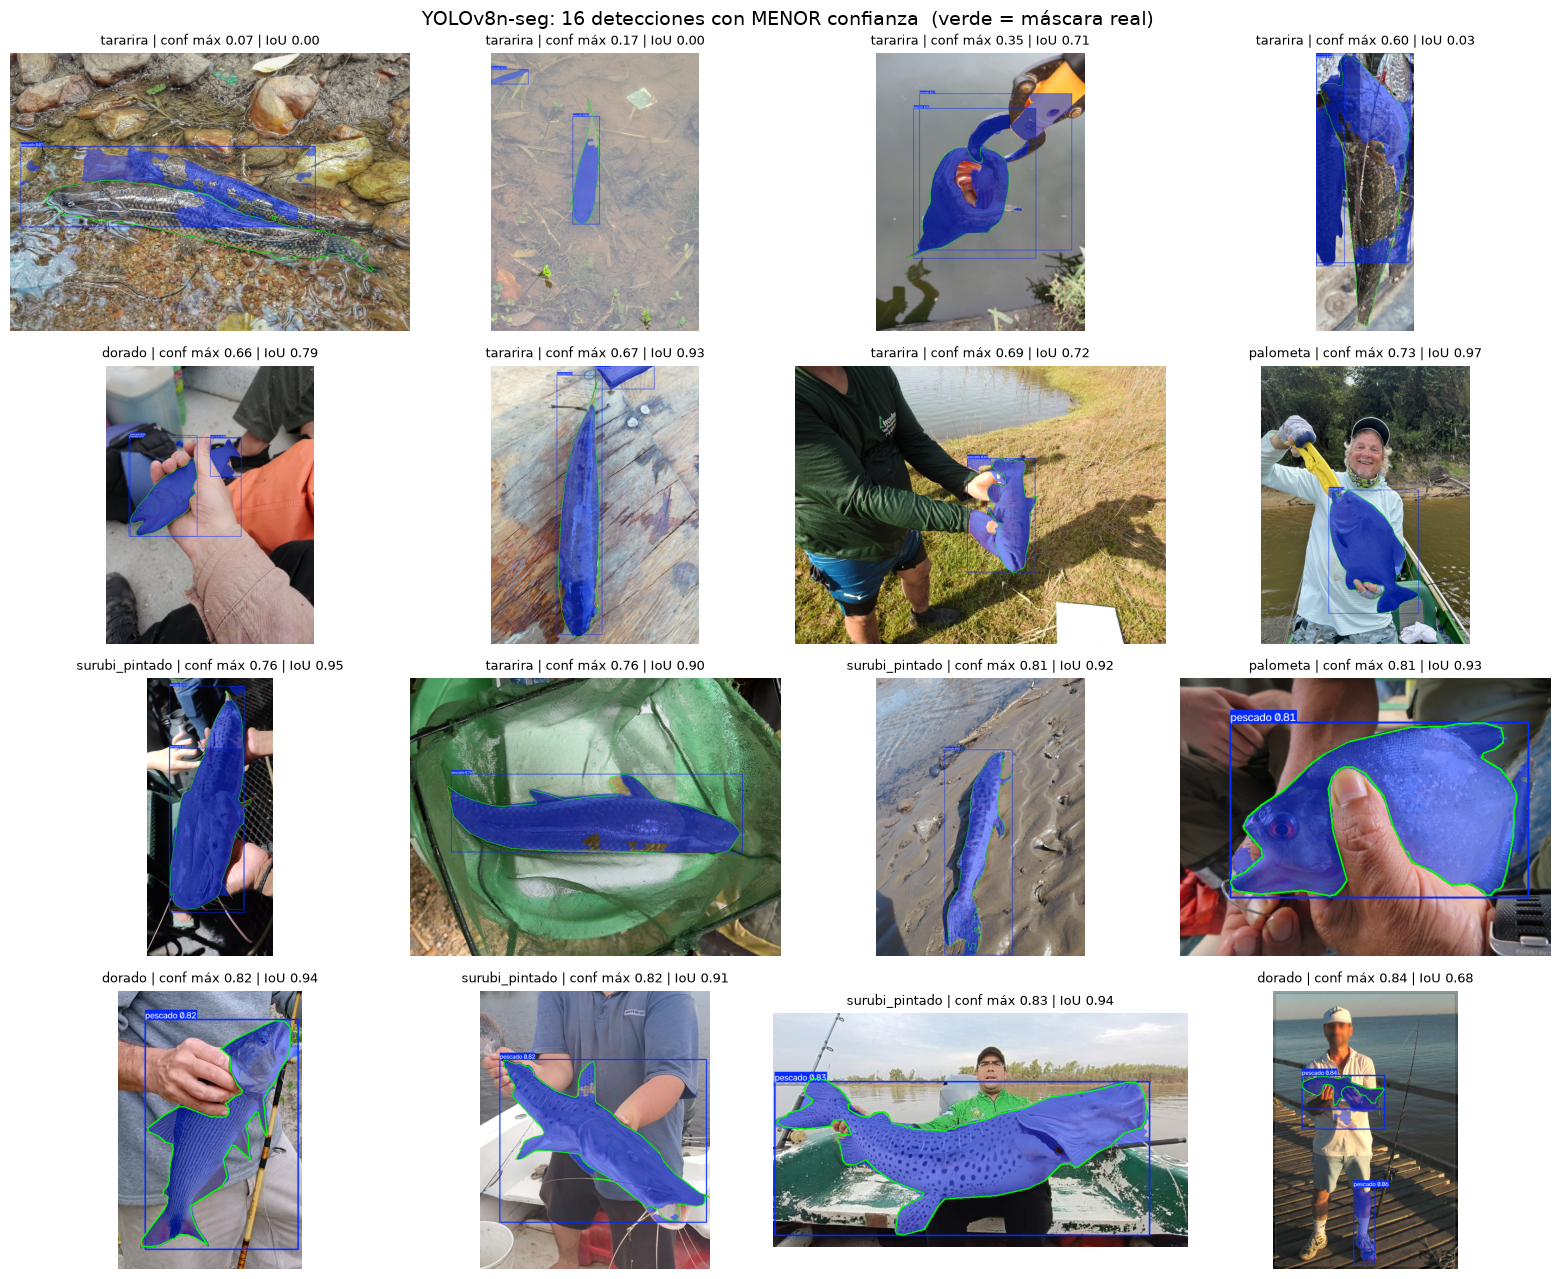

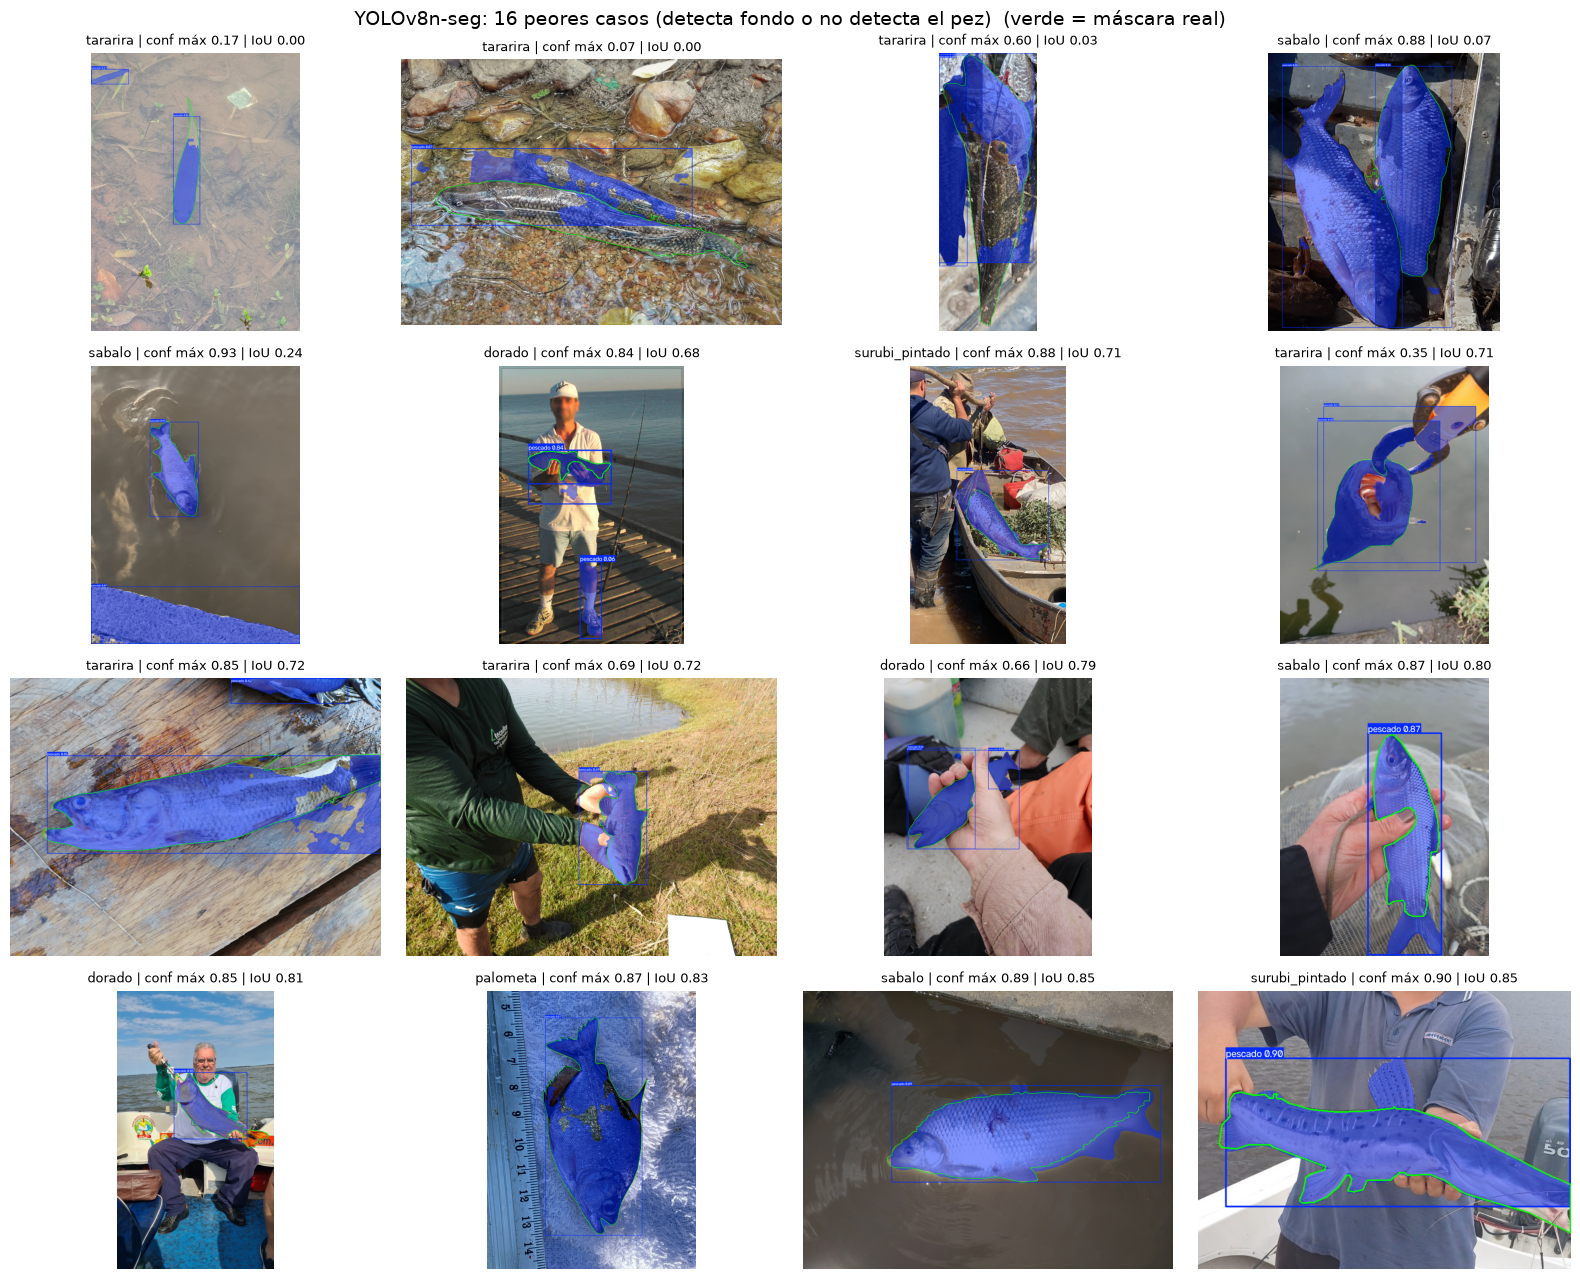

In [12]:
import matplotlib.pyplot as plt

best_v8 = YOLO(RUNS / "yolov8n-seg" / "weights" / "best.pt")
PLOT_CONF = 0.05   # umbral bajo para ver también detecciones débiles
N_EX = 16

def predict_img(model, r, split="val", conf=PLOT_CONF):
    f = OUT / "images" / split / dst_name(r)
    return model.predict(str(f), imgsz=HYP["imgsz"], conf=conf, retina_masks=True, verbose=False)[0]

def val_stats(model, split="val"):
    rows = []
    for r in df[df.split == split].to_dict("records"):
        res = predict_img(model, r, split)
        h, w = r["height"], r["width"]
        conf = res.boxes.conf.cpu().numpy() if len(res.boxes) else np.zeros(0)
        pm = np.zeros((h, w), bool)
        if res.masks is not None and (conf >= CONF).any():
            pm = res.masks.data.cpu().numpy()[conf >= CONF].any(0)
            if pm.shape != (h, w):
                pm = cv2.resize(pm.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        gm = gt_mask(r["polygons"], h, w)
        rows.append(dict(rec=r, max_conf=float(conf.max()) if len(conf) else 0.0,
                         iou=float((pm & gm).sum() / max((pm | gm).sum(), 1)), pred_area=int(pm.sum())))
    return pd.DataFrame(rows)

def plot_examples(model, sel, title, fname, split="val"):
    fig, axes = plt.subplots(4, 4, figsize=(16, 13))
    for ax, (_, s) in zip(axes.ravel(), sel.iterrows()):
        r = s["rec"]
        res = predict_img(model, r, split)
        im = res.plot(line_width=2, font_size=10)                      # BGR con máscara, caja y confianza
        for poly in r["polygons"]:                                      # contorno real
            cv2.polylines(im, [np.round(np.array(poly).reshape(-1, 2)).astype(np.int32)], True, (0, 255, 0), 2)
        ax.imshow(im[..., ::-1]); ax.axis("off")
        ax.set_title(f"{r['species']} | conf máx {s['max_conf']:.2f} | IoU {s['iou']:.2f}", fontsize=9)
    for ax in axes.ravel()[len(sel):]:
        ax.axis("off")
    fig.suptitle(title + "  (verde = máscara real)", fontsize=14)
    plt.tight_layout(); fig.savefig(RUNS / fname, dpi=110); plt.show()

st = val_stats(best_v8)
plot_examples(best_v8, st.sort_values("max_conf", ascending=False).head(N_EX),
              "YOLOv8n-seg: 16 detecciones con MAYOR confianza", "examples_v8_high_conf.png")
plot_examples(best_v8, st[st.max_conf > 0].sort_values("max_conf").head(N_EX),
              "YOLOv8n-seg: 16 detecciones con MENOR confianza", "examples_v8_low_conf.png")
plot_examples(best_v8, st.assign(_none=st.pred_area == 0).sort_values(["iou", "_none", "max_conf"], ascending=[True, True, False]).head(N_EX),
              "YOLOv8n-seg: 16 peores casos (detecta fondo o no detecta el pez)", "examples_v8_failures.png")

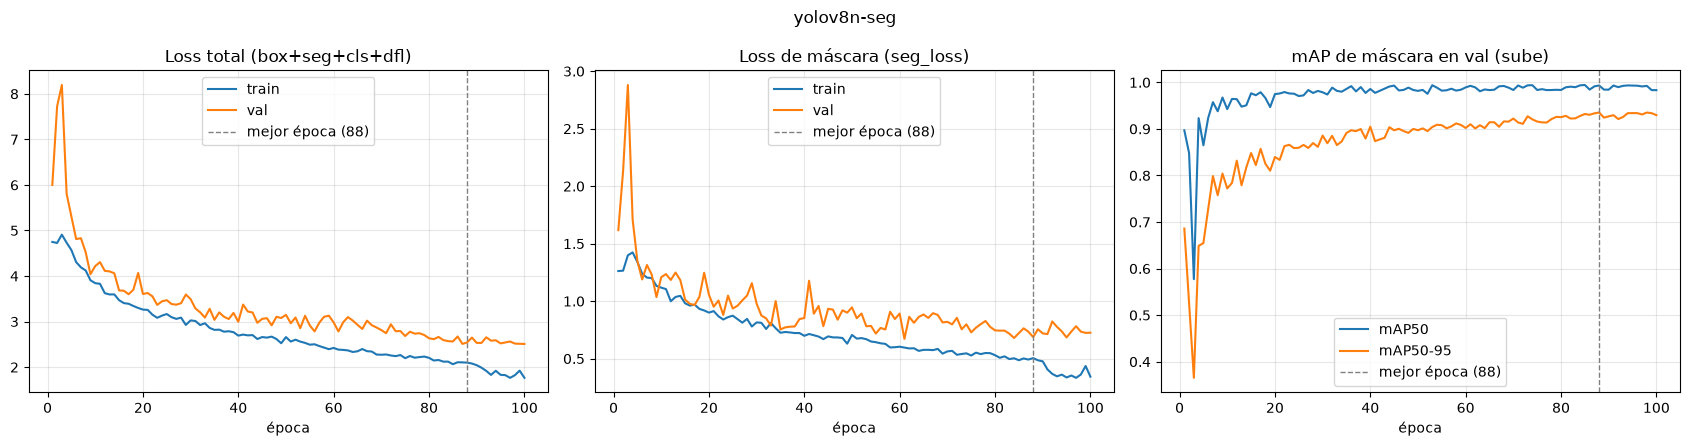

In [4]:
log = pd.read_csv(RUNS / "yolov8n-seg" / "results.csv"); log.columns = log.columns.str.strip()
plot_training(log, "yolov8n-seg", int(log.loc[log["metrics/mAP50-95(M)"].idxmax(), "epoch"]))